# Описание проекта


**Данные:** сгенерированный датасет, имитирующий маркетинговую активность B2B-компании. 
500 лидов из 5 каналов привлечения, 2024–2025 гг.

**Что внутри:**
*   `lead_id` — ID лида
*   `channel` — канал привлечения (конференции, вебинары, платный трафик, партнёры, тендеры)
*   `segment` — отрасль клиента (энергетика, ритейл, нефтегаз, верфи, госсектор, сетевые компании)
*   `created_date` — дата создания лида
*   `is_won` — флаг: 1 = сделка, 0 = проигрыш
*   `won_date` — дата сделки
*   `deal_value` — сумма сделки, ₽
*   `lead_cost` — стоимость привлечения лида, ₽

**Задачи ноутбука:**
*   Провести первичный анализ лидов и конверсии.
*   Построить воронку лидогенерации: лиды → квалифицированные → сделки.
*   Проанализировать конверсию, CAC и ROMI по каналам привлечения.
*   Построить когортный анализ retention продавцов.
*   Сформулировать инсайты и рекомендации для маркетинга.

**Инструменты:** Python (pandas, numpy, scipy, seaborn), DataLens.


# 2. Загрузка и первичный анализ

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Палитра в синих тонах
selected_palette = sns.color_palette("Blues", n_colors=20)

# Загрузка данных
path = os.path.join('..', 'data', 'raw')
df = pd.read_csv(os.path.join(path, 'marketing_leads.csv'))

print(f"Всего лидов: {len(df)}")
print(f"Сделок: {df['is_won'].sum()} (конверсия: {df['is_won'].mean():.1%})")
print(f"Затраты на маркетинг: {df['lead_cost'].sum():,.0f} ₽")
print(f"Выручка: {df['deal_value'].sum():,.0f} ₽")
print(f"\nПериод: {df['created_date'].min()} — {df['created_date'].max()}")
print(f"\nПропуски:")
print(df.isnull().sum())

Всего лидов: 500
Сделок: 73 (конверсия: 14.6%)
Затраты на маркетинг: 1,717,500 ₽
Выручка: 20,956,037 ₽

Период: 2024-01-02 — 2025-06-30

Пропуски:
lead_id           0
channel           0
segment           0
created_date      0
is_won            0
won_date        427
deal_value        0
lead_cost         0
dtype: int64


In [23]:
# Каналы привлечения
print("=== Лиды по каналам ===")
print(df['channel'].value_counts())

print("\n=== Лиды по отраслям ===")
print(df['segment'].value_counts())

=== Лиды по каналам ===
channel
Партнёры          111
Тендеры           101
Вебинары          100
Конференции        97
Платный трафик     91
Name: count, dtype: int64

=== Лиды по отраслям ===
segment
Госсектор           100
Верфи                95
Энергетика           84
Сетевая компания     82
Нефтегаз             70
Ритейл               69
Name: count, dtype: int64


**Первичный анализ:**

*   500 лидов из 5 каналов, 73 сделки. Общая конверсия — 14.6%.
*   Каналы распределены равномерно: от 91 до 111 лидов на канал.
*   Отрасли также без сильного перекоса: от 69 до 100 лидов.
*   427 пропусков в `won_date`  это лиды без сделки.
*   Период: январь 2024 — июнь 2025 (18 месяцев).
*   Затраты на маркетинг: 1.72M ₽, выручка от сделок: 20.96M ₽.
*   **Общий ROMI: 1120%** — маркетинг окупается более чем в 11 раз.

#  3. Воронка лидогенерации

#### Строим воронку: от лида до сделки

In [24]:
# Этапы воронки
total_leads = len(df)
won_deals = df['is_won'].sum()

# Квалифицированные: лиды, у которых известен сегмент (все, кроме пропусков)
qualified = df['segment'].notna().sum()

# Выручка
total_revenue = df['deal_value'].sum()
total_cost = df['lead_cost'].sum()

# Строим воронку
funnel_stages = ['Лиды', 'Квалифицированные', 'Сделки', 'Выручка (₽)']
funnel_values = [total_leads, qualified, won_deals, total_revenue]

# Конверсия step-by-step
print("=== Воронка лидогенерации ===")
prev = funnel_values[0]
for stage, value in zip(funnel_stages, funnel_values):
    if stage == 'Выручка (₽)':
        print(f"{stage}: {value:,.0f} ₽ (средний чек: {value/won_deals:,.0f} ₽)" if won_deals > 0 else f"{stage}: 0 ₽")
    else:
        conv = value / prev * 100 if prev > 0 else 0
        print(f"{stage}: {value} (конверсия: {conv:.0f}%)")
        prev = value

print(f"\nОбщая конверсия: {won_deals / total_leads * 100:.1f}%")
print(f"Стоимость лида (CPL): {total_cost / total_leads:,.0f} ₽")
print(f"Стоимость привлечения клиента (CAC): {total_cost / won_deals:,.0f} ₽" if won_deals > 0 else "CAC: —")
print(f"ROMI: {(total_revenue - total_cost) / total_cost * 100:.0f}%")

=== Воронка лидогенерации ===
Лиды: 500 (конверсия: 100%)
Квалифицированные: 500 (конверсия: 100%)
Сделки: 73 (конверсия: 15%)
Выручка (₽): 20,956,037 ₽ (средний чек: 287,069 ₽)

Общая конверсия: 14.6%
Стоимость лида (CPL): 3,435 ₽
Стоимость привлечения клиента (CAC): 23,527 ₽
ROMI: 1120%


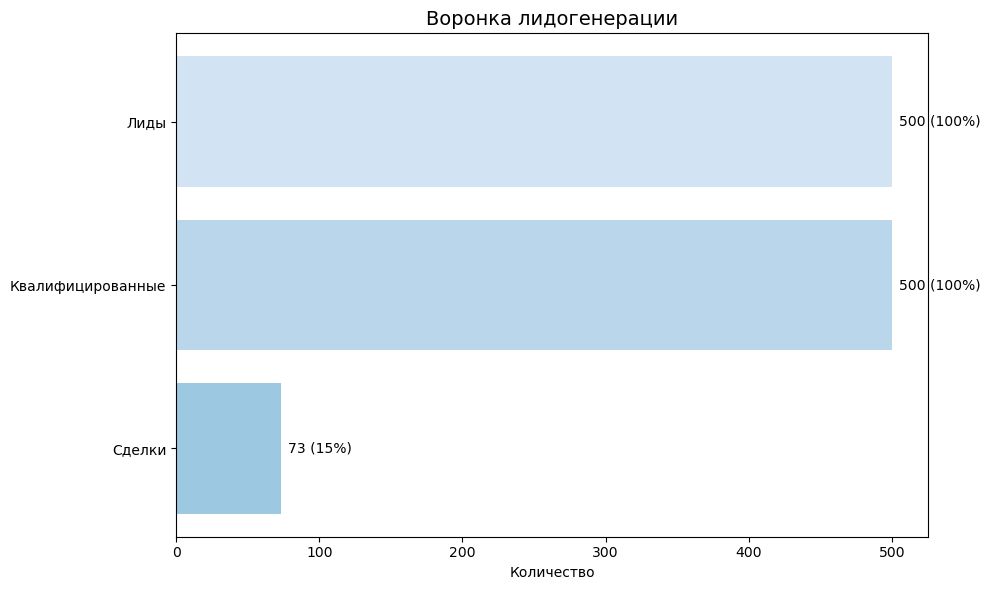

In [25]:
# Визуализация воронки
funnel_colors = [selected_palette[3], selected_palette[5], selected_palette[7], selected_palette[9]]
funnel_stages_3 = ['Лиды', 'Квалифицированные', 'Сделки']
funnel_values_3 = [total_leads, qualified, won_deals]

plt.figure(figsize=(10, 6))
bars = plt.barh(funnel_stages_3, funnel_values_3, color=funnel_colors)
plt.title('Воронка лидогенерации', fontsize=14)
plt.xlabel('Количество')
plt.gca().invert_yaxis()

for bar, value in zip(bars, funnel_values_3):
    plt.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2, 
             f'{value} ({value/total_leads*100:.0f}%)', va='center')

plt.tight_layout()
plt.show()

**Воронка лидогенерации:**

*   Из 500 лидов в сделки конвертировались 73 (14.6%).
*   Средний чек сделки — 287 069 ₽.
*   CPL (стоимость лида) — 3 435 ₽ в среднем по всем каналам.
*   CAC (стоимость привлечения клиента) — 23 527 ₽.
*   ROMI: 1120% — каждый рубль, вложенный в маркетинг, принёс 11.2 рубля выручки.
*   **Важно:** конверсия 100% на этапе «Лиды — Квалифицированные» — у всех лидов заполнен сегмент. В реальности часть лидов отсеивается на квалификации, но в наших данных этого нет.

#  4. Анализ по каналам привлечения

#### Сравниваем каналы по конверсии, CAC и ROMI.

In [26]:
# Сводка по каналам
channel_stats = df.groupby('channel').agg(
    leads=('lead_id', 'count'),
    won=('is_won', 'sum'),
    total_cost=('lead_cost', 'sum'),
    total_revenue=('deal_value', 'sum')
).reset_index()

channel_stats['conversion'] = (channel_stats['won'] / channel_stats['leads'] * 100).round(1)
channel_stats['cpl'] = (channel_stats['total_cost'] / channel_stats['leads']).round(0).astype(int)
channel_stats['cac'] = (channel_stats['total_cost'] / channel_stats['won']).round(0).astype(int)
channel_stats['romi'] = np.where(
    channel_stats['total_cost'] > 0,
    ((channel_stats['total_revenue'] - channel_stats['total_cost']) / channel_stats['total_cost'] * 100).round(0),
    np.inf
)

# Сортируем по ROMI
channel_stats = channel_stats.sort_values('romi', ascending=False)

print("=== Эффективность каналов ===")
print(f"{'Канал':<20} {'Лидов':>6} {'Сделок':>6} {'Конв.':>7} {'CPL':>8} {'CAC':>8} {'ROMI':>8}")
print("-" * 75)
for _, row in channel_stats.iterrows():
    romi_str = f"{row['romi']:>7.0f}%" if row['romi'] != np.inf else "      —"
    cpl_str = f"{row['cpl']:>7,}".replace(',', ' ')
    cac_str = f"{row['cac']:>7,}".replace(',', ' ')
    print(f"{row['channel']:<20} {row['leads']:>6} {row['won']:>6} {row['conversion']:>6.1f}% {cpl_str} {cac_str} {romi_str}")

=== Эффективность каналов ===
Канал                 Лидов Сделок   Конв.      CPL      CAC     ROMI
---------------------------------------------------------------------------
Партнёры                111     28   25.2%       0       0       —
Вебинары                100     16   16.0%   3 000  18 750    1338%
Конференции              97     18   18.6%   8 000  43 111     612%
Платный трафик           91      3    3.3%   1 500  45 500     597%
Тендеры                 101      8    7.9%   5 000  63 125     403%


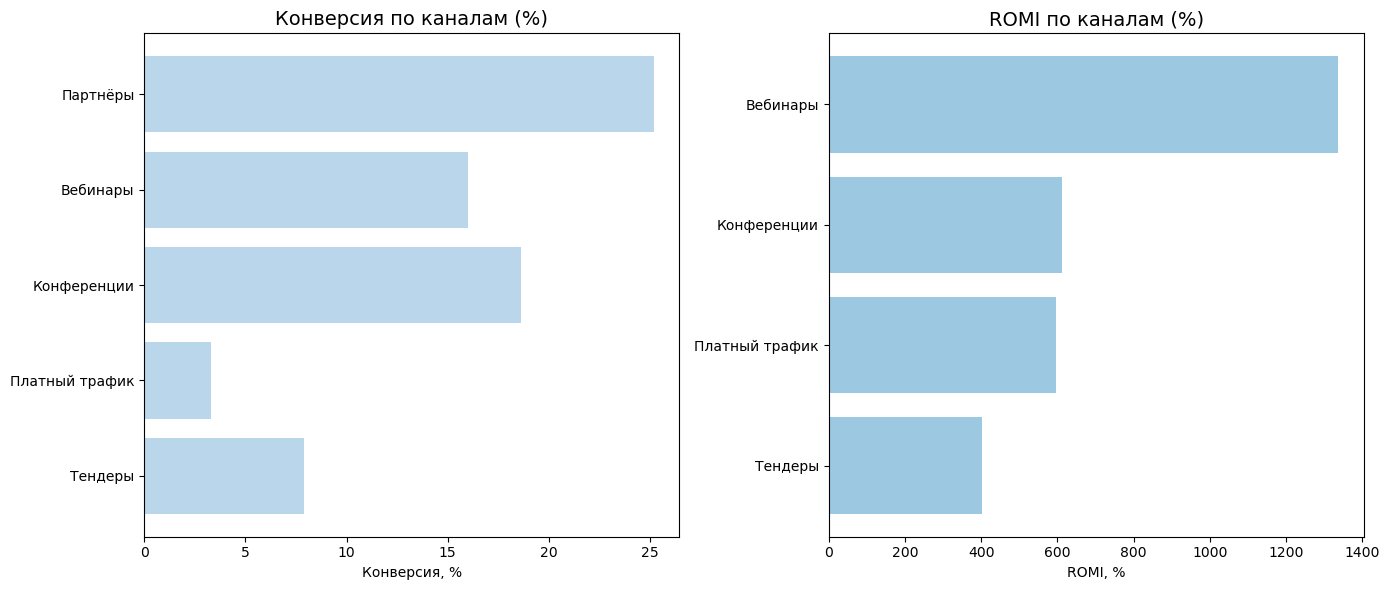

In [27]:
# Визуализация: конверсия по каналам
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Конверсия
axes[0].barh(channel_stats['channel'], channel_stats['conversion'], color=selected_palette[5])
axes[0].set_title('Конверсия по каналам (%)', fontsize=14)
axes[0].set_xlabel('Конверсия, %')
axes[0].invert_yaxis()

# ROMI (без партнёров — у них ∞)
channel_stats_romi = channel_stats[channel_stats['romi'] != np.inf]
axes[1].barh(channel_stats_romi['channel'], channel_stats_romi['romi'], color=selected_palette[7])
axes[1].set_title('ROMI по каналам (%)', fontsize=14)
axes[1].set_xlabel('ROMI, %')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

**Анализ по каналам:**

*   **Партнёры** — лучший канал: конверсия 25.2%, CAC = 0 (лиды бесплатные). ROMI стремится к бесконечности. Но поток нестабильный — нужно развивать партнёрскую программу.
*   **Вебинары** — отличный ROMI (1338%) при умеренном CAC (18 750 ₽). Хороший баланс стоимости и качества лидов.
*   **Конференции** — высокая конверсия (18.6%), но CAC дорогой (43 111 ₽). ROMI 612% — достойно, но уступает вебинарам.
*   **Платный трафик** — самая низкая конверсия (3.3%) при высоком CAC (45 500 ₽). ROMI 597% — кажется хорошим, но это за счёт крупных сделок. Рискованный канал: можно слить бюджет, не получив ни одной сделки.
*   **Тендеры** — конверсия 7.9%, самый высокий CAC (63 125 ₽). ROMI 403% — канал для госсектора, отказываться нельзя, но оптимизировать нужно.

**Вывод:** основной бюджет — на вебинары и конференции. Партнёров развивать системно. Платный трафик — точечно, только на проверенные сегменты. Тендеры — продолжать, но без увеличения бюджета.

#  5. Когортный анализ retention продавцов

#### Смотрим, сколько продавцов остаются активными через N месяцев после сделки.

In [28]:
# Кумулятивная выручка по когортам
won_df = df[df['is_won'] == 1].copy()
won_df['won_month'] = pd.to_datetime(won_df['won_date']).dt.to_period('M')
won_df['won_month_str'] = won_df['won_month'].astype(str)

# Средняя сделка по когорте
cohort_revenue = won_df.groupby('won_month_str')['deal_value'].agg(['count', 'sum', 'mean']).round(0)
cohort_revenue.columns = ['Сделок', 'Общая выручка', 'Средний чек']

cohort_revenue

,Сделок,Общая выручка,Средний чек
won_month_str,,,
2024-02,2,603211,301606.0
2024-03,2,775927,387964.0
2024-04,1,214014,214014.0
2024-05,2,679309,339654.0
2024-06,1,275150,275150.0
2024-07,3,1170444,390148.0
2024-08,6,1308718,218120.0
2024-09,7,2322835,331834.0
2024-10,5,1875268,375054.0


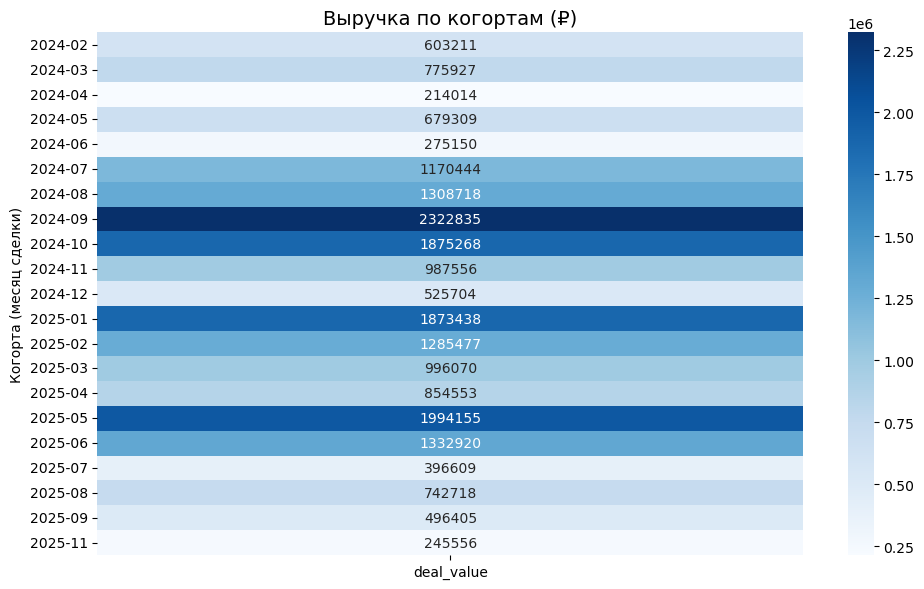

In [29]:
# Тепловая карта выручки по когортам
cohort_pivot = won_df.pivot_table(
    values='deal_value', 
    index='won_month_str', 
    aggfunc='sum'
).sort_index()

plt.figure(figsize=(10, 6))
sns.heatmap(cohort_pivot, annot=True, fmt='.0f', cmap='Blues')
plt.title('Выручка по когортам (₽)', fontsize=14)
plt.ylabel('Когорта (месяц сделки)')
plt.tight_layout()
plt.show()

**Выручка по когортам:**

*   Лучшие когорты по выручке: 2024-09 (2.3M, 7 сделок), 2025-01 (1.9M, 5 сделок), 2024-10 (1.9M, 5 сделок).
*   Средний чек варьируется от 197K до 390K — зависит от отрасли и сегмента, а не от канала.
*   Спад к концу 2025 года ожидаем — у поздних когорт меньше времени накопить выручку.



## 6. Ключевые инсайты и рекомендации

### Воронка лидогенерации

**Что увидели:** Из 500 лидов в сделки конвертировались 73 (14.6%). CPL — 3 435 ₽, CAC — 23 527 ₽. ROMI — 1120%.

**Инсайт:** Общая эффективность маркетинга высокая — каждый вложенный рубль приносит 11 рублей выручки. Но конверсия 14.6% означает, что 85% лидов не доходят до сделки.

**Рекомендация:** Проанализировать причины отсева. Возможно, часть лидов некачественная — перераспределить бюджет в пользу каналов с лучшей конверсией.

---

### Анализ по каналам

**Что увидели:**
- Партнёры: конверсия 25.2%, CAC = 0
- Вебинары: конверсия 16.0%, ROMI = 1338%.
- Конференции: конверсия 18.6%, ROMI = 612%.
- Платный трафик: конверсия 3.3%, ROMI = 597%.
- Тендеры: конверсия 7.9%, ROMI = 403%.

**Инсайт:** Платный трафик даёт самую низкую конверсию при высоком CAC. Вебинары — лучший баланс стоимости и качества. Партнёры — лучший канал, но поток нестабильный.

**Рекомендация:**
- Основной бюджет — на вебинары и конференции.
- Партнёрскую программу развивать системно: реферальные бонусы, совместные мероприятия.
- Платный трафик урезать до минимума, оставить только на проверенные сегменты.
- Тендеры продолжать для госсектора, но без увеличения бюджета.

---

### Выручка по когортам

**Что увидели:** Лучшие когорты — 2024-09 (2.3M), 2025-01 (1.9M). Средний чек стабилен — 250-350K.

**Инсайт:** Выручка зависит от количества сделок в когорте, а не от их размера. Средний чек не растёт со временем — нет инфляции цен.

**Рекомендация:** Сфокусироваться на увеличении количества сделок, а не на повышении среднего чека. Масштабировать успешные каналы.

---

### Итог: что делать бизнесу

1. **Вебинары — приоритет №1.** Лучший ROMI, стабильный поток лидов. Увеличить частоту.
2. **Партнёры — приоритет №2.** Запустить реферальную программу, совместные вебинары.
3. **Конференции — оставить как есть.** Дорого, но конверсия высокая.
4. **Платный трафик — урезать.** Оставить только на брендовые запросы.
5. **Тендеры — продолжать.** Стратегический канал для госсектора.

## 7. Маркетинговый дашборд

Интерактивный дашборд в Yandex DataLens: [Marketing Analytics Dashboard](https://datalens.ru/d2i8fxm3r1k8w-marketingovaya-analitika)

На дашборде представлены ключевые метрики и воронки для оценки эффективности маркетинговых каналов:
*   **Ключевые метрики**: общее количество лидов, конверсия, стоимость лида (CPL) и возврат инвестиций (ROMI).
*   **Воронка лидогенерации**: визуализация пути от лида до сделки.
*   **Анализ по каналам**: конверсия и ROMI в разрезе каждого канала привлечения (исключая партнёров с бесконечным ROMI).
*   **Динамика выручки**: тренд суммы сделок по месяцам.

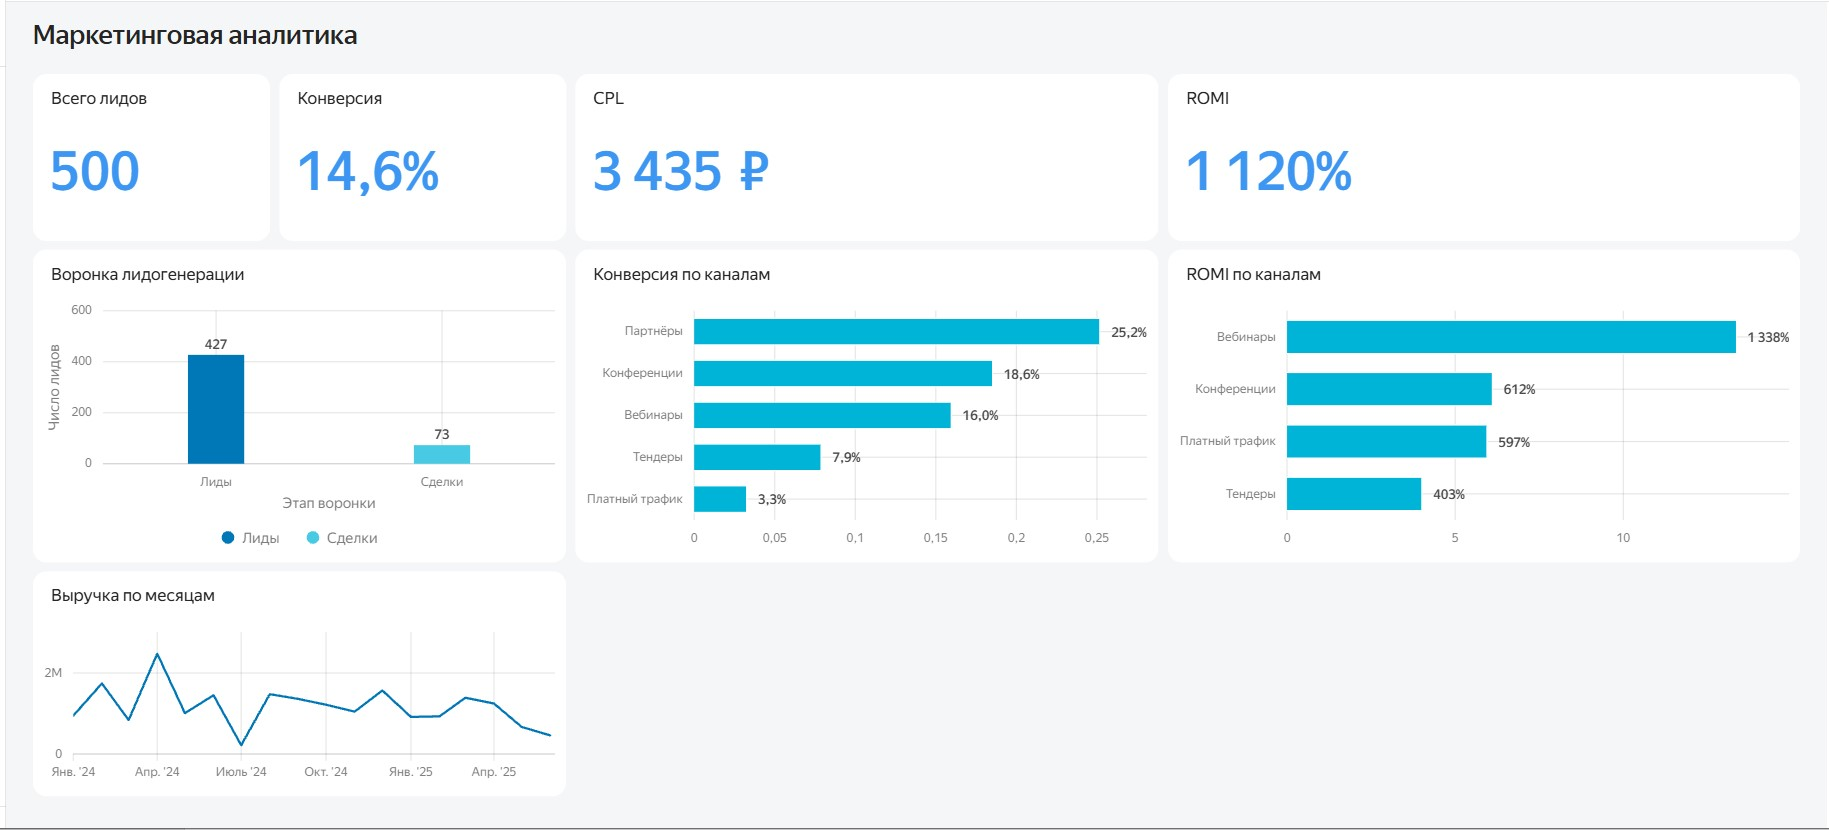